# Unemployment Analysis — India, 2020
**Oasis Infobyte SIP — Data Science Task 2** · Steven Manuel Rios

Dataset: *Unemployment in India* (CMIE data, monthly by state, Jan–Oct 2020), from the public Kaggle dataset (mirror in `data/unemployment_2020.csv`). Goal: measure how COVID-19 and the national lockdown that began on 25 March 2020 affected unemployment.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

## 1. Load, inspect, clean & convert types

In [2]:
df = pd.read_csv("data/unemployment_2020.csv")
df.columns = [c.strip() for c in df.columns]          # raw headers contain leading spaces
df = df.rename(columns={"Region": "State", "Region.1": "Zone",
                        "Estimated Unemployment Rate (%)": "Unemployment_Rate",
                        "Estimated Employed": "Employed",
                        "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate"})
df["Date"] = pd.to_datetime(df["Date"].str.strip(), dayfirst=True)
df["Frequency"] = df["Frequency"].str.strip()
print("Shape:", df.shape); print(df.dtypes); print("\nNulls:\n", df.isnull().sum())
df.head()

Shape: (267, 9)
State                                   str
Date                         datetime64[us]
Frequency                               str
Unemployment_Rate                   float64
Employed                              int64
Labour_Participation_Rate           float64
Zone                                    str
longitude                           float64
latitude                            float64
dtype: object

Nulls:
 State                        0
Date                         0
Frequency                    0
Unemployment_Rate            0
Employed                     0
Labour_Participation_Rate    0
Zone                         0
longitude                    0
latitude                     0
dtype: int64


,State,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Zone,longitude,latitude
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74


In [3]:
df.describe()

,Date,Unemployment_Rate,Employed,Labour_Participation_Rate,longitude,latitude
count,267,267.000000,2.670000e+02,267.000000,267.000000,267.000000
mean,2020-06-16 09:15:30.337078,12.236929,1.396211e+07,41.681573,22.826048,80.532425
min,2020-01-31 00:00:00,0.500000,1.175420e+05,16.770000,10.850500,71.192400
25%,2020-03-31 00:00:00,4.845000,2.838930e+06,37.265000,18.112400,76.085600
50%,2020-06-30 00:00:00,9.650000,9.732417e+06,40.390000,23.610200,79.019300
75%,2020-08-31 00:00:00,16.755000,2.187869e+07,44.055000,27.278400,85.279900
max,2020-10-31 00:00:00,75.850000,5.943376e+07,69.690000,33.778200,92.937600
std,NaN,10.803283,1.336632e+07,7.845419,6.270731,5.831738


## 2. Region-wise and month-wise EDA

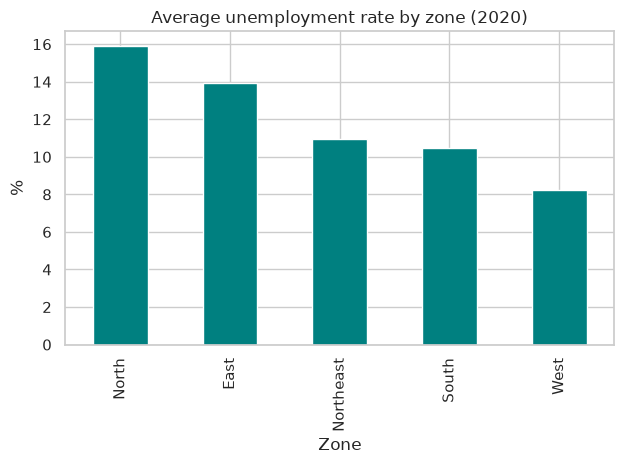

Zone
North        15.89
East         13.92
Northeast    10.95
South        10.45
West          8.24
Name: Unemployment_Rate, dtype: float64

In [4]:
zone = df.groupby("Zone")["Unemployment_Rate"].mean().sort_values(ascending=False)
zone.plot.bar(color="teal", title="Average unemployment rate by zone (2020)"); plt.ylabel("%"); save("zone_avg")
zone.round(2)

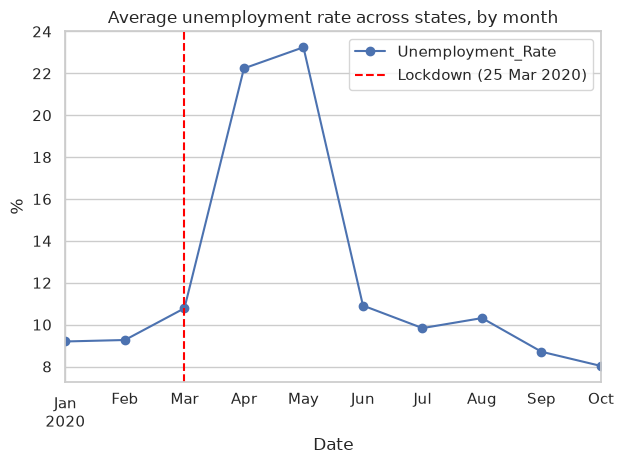

Date
2020-01     9.20
2020-02     9.27
2020-03    10.78
2020-04    22.24
2020-05    23.24
2020-06    10.91
2020-07     9.83
2020-08    10.31
2020-09     8.71
2020-10     8.03
Freq: M, Name: Unemployment_Rate, dtype: float64

In [5]:
monthly = df.groupby(df["Date"].dt.to_period("M"))["Unemployment_Rate"].mean()
monthly.plot(marker="o", title="Average unemployment rate across states, by month"); plt.ylabel("%")
plt.axvline(pd.Period("2020-03", "M"), color="red", ls="--", label="Lockdown (25 Mar 2020)"); plt.legend(); save("monthly_trend")
monthly.round(2)

**Observation:** The average rate is steady at about 9–11% from January to March, then **jumps to about 22–23% in April–May**, the strict lockdown months. It falls back to about 10% by June and keeps declining to about 8% by October, slightly *below* the pre-COVID level.

## 3. Time-series for major states

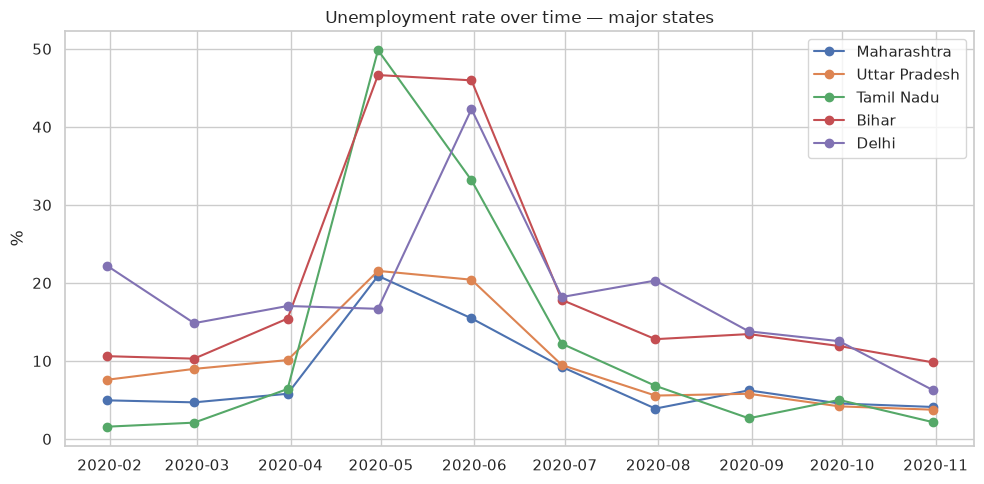

In [6]:
states = ["Maharashtra", "Uttar Pradesh", "Tamil Nadu", "Bihar", "Delhi"]
plt.figure(figsize=(10, 5))
for s in states:
    d = df[df["State"] == s]; plt.plot(d["Date"], d["Unemployment_Rate"], marker="o", label=s)
plt.title("Unemployment rate over time — major states"); plt.ylabel("%"); plt.legend(); save("states_timeseries")

**Observation:** Every state shows the April–May spike, but its size varies widely. Tamil Nadu (peak ≈ 49.8%), Bihar (≈ 46.6%) and Delhi (≈ 42.3%) spike sharply. Maharashtra (≈ 20.9%) and Uttar Pradesh (≈ 21.5%) peak much lower.

## 4. Top 10 states by average unemployment rate

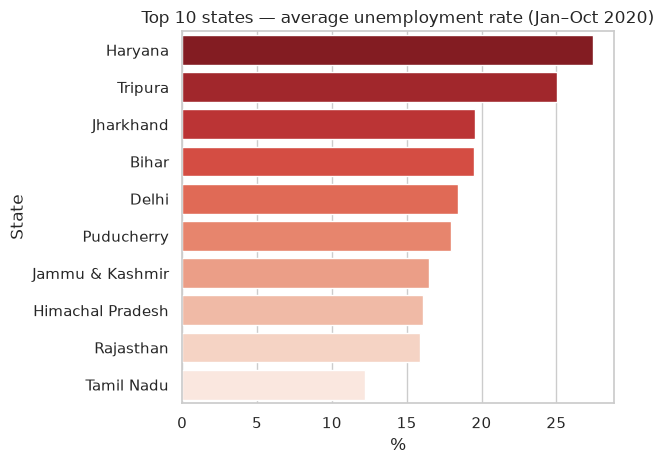

State
Haryana             27.48
Tripura             25.06
Jharkhand           19.54
Bihar               19.47
Delhi               18.41
Puducherry          17.94
Jammu & Kashmir     16.48
Himachal Pradesh    16.07
Rajasthan           15.87
Tamil Nadu          12.19
Name: Unemployment_Rate, dtype: float64

In [7]:
top = df.groupby("State")["Unemployment_Rate"].mean().nlargest(10)
sns.barplot(x=top.values, y=top.index, palette="Reds_r"); plt.title("Top 10 states — average unemployment rate (Jan–Oct 2020)"); plt.xlabel("%"); save("top10_states")
top.round(2)

**Observation:** Haryana (~27.5%) and Tripura (~25%) have the highest averages, followed by Jharkhand, Bihar and Delhi (~18–20%). For several of these states, high unemployment was a structural problem before COVID as well.

## 5. Correlation heatmap

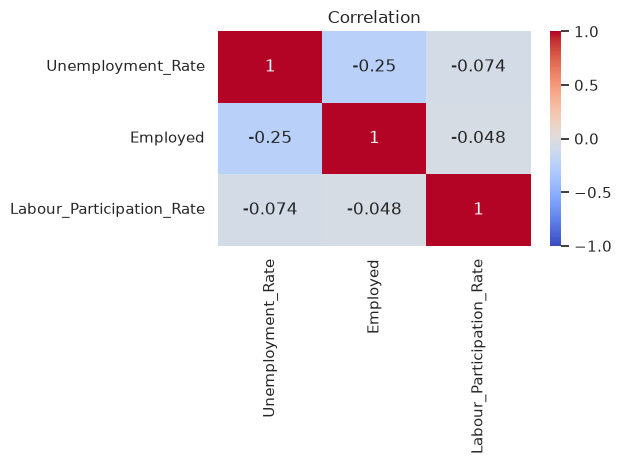

In [8]:
sns.heatmap(df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation"); save("correlation")

**Observation:** Unemployment rate correlates only weakly and negatively with the number employed (≈ −0.25) and has almost no correlation with labour participation (≈ −0.07). The *Employed* figure mostly reflects state population size, so it says little about the rate itself.

## 6. Pre-COVID vs post-COVID comparison
The split is at 1 April 2020: Jan–Mar is *pre-lockdown* and Apr–Oct is *lockdown and after*.

                      Unemployment_Rate  Labour_Participation_Rate
Period                                                            
Post-COVID (Apr–Oct)              13.28                      40.63
Pre-COVID (Jan–Mar)                9.76                      44.18


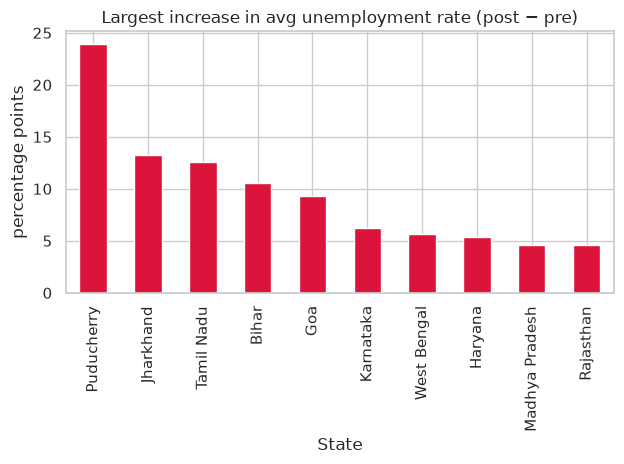

Period,Post-COVID (Apr–Oct),Pre-COVID (Jan–Mar),Change
State,,,
Puducherry,25.13,1.18,23.95
Jharkhand,23.53,10.23,13.30
Tamil Nadu,15.97,3.35,12.62
Bihar,22.63,12.11,10.52
Goa,14.96,5.65,9.31
Karnataka,9.54,3.31,6.23
West Bengal,11.88,6.26,5.62
Haryana,29.09,23.72,5.37
Madhya Pradesh,8.23,3.63,4.60


In [9]:
df["Period"] = np.where(df["Date"] < "2020-04-01", "Pre-COVID (Jan–Mar)", "Post-COVID (Apr–Oct)")
cmp = df.groupby("Period")[["Unemployment_Rate", "Labour_Participation_Rate"]].mean().round(2)
print(cmp)
change = (df.pivot_table(index="State", columns="Period", values="Unemployment_Rate")
            .assign(Change=lambda t: t["Post-COVID (Apr–Oct)"] - t["Pre-COVID (Jan–Mar)"]).sort_values("Change", ascending=False))
change["Change"].head(10).plot.bar(color="crimson", title="Largest increase in avg unemployment rate (post − pre)"); plt.ylabel("percentage points"); save("pre_post_change")
change.head(10).round(2)

## 7. Conclusions
- The national average unemployment rate rose from **≈9.8% before COVID to ≈13.3% from April onward**, a rise of about 3.5 percentage points driven almost entirely by April and May.
- The impact was very uneven across states. Some had extreme lockdown spikes and others were barely affected.
- Recovery was fast. By September–October, rates were at or below January levels, which suggests the shock was temporary and tied to the lockdown rather than permanent job losses.
- Labour participation also dipped during the lockdown months, so the headline rate *understates* the full shock: many people left the labour force altogether.